Objetivo:

Comparar dos técnicas de Transfer Learning en Keras:

(a) solo extraer características (congelar capas)

(b) fine-tunear (descongelar últimas capas)

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Cargar CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train = tf.image.resize(x_train, (96, 96)) / 255.0
x_test = tf.image.resize(x_test, (96, 96)) / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [3]:
def build_model(trainable_layers=None):
    # Modelo base MobileNetV2
    base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(96,96,3))

    if trainable_layers is None:
        # a) Feature extraction: congelar todas las capas
        base_model.trainable = False
    else:
        # b) Fine-tuning: descongelar las últimas N capas
        base_model.trainable = True
        for layer in base_model.layers[:-trainable_layers]:
            layer.trainable = False

    # Capas superiores
    x = GlobalAveragePooling2D()(base_model.output)
    x = Dropout(0.3)(x)
    output = Dense(10, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=output)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

La siguiente celda entrena el modelo y toma aproximadamente 30 minutos de tiempo de ejecución.

In [4]:
# ----------------------------------------
# Modelo 1: Feature Extraction (todas las capas congeladas)
model_fe = build_model(trainable_layers=None)
history_fe = model_fe.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test), batch_size=64)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 385s 485ms/step - accuracy: 0.5930 - loss: 1.2023 - val_accuracy: 0.7805 - val_loss: 0.6366
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 384s 487ms/step - accuracy: 0.7544 - loss: 0.7034 - val_accuracy: 0.7727 - val_loss: 0.6451
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 379s 483ms/step - accuracy: 0.7705 - loss: 0.6619 - val_accuracy: 0.7932 - val_loss: 0.5984
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 388s 491ms/step - accuracy: 0.7720 - loss: 0.6528 - val_accuracy: 0.7934 - val_loss: 0.5939
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 435s 481ms/step - accuracy: 0.7727 - loss: 0.6488 - val_accuracy: 0.7983 - val_loss: 0.5745


La siguiente celda entrena el modelo y toma aproximadamente 40 minutos de tiempo de ejecución.

In [5]:
# ----------------------------------------
# Modelo 2: Fine-Tuning (descongelar las últimas 20 capas)
model_ft = build_model(trainable_layers=20)
history_ft = model_ft.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test), batch_size=64)

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 512s 642ms/step - accuracy: 0.7453 - loss: 0.7733 - val_accuracy: 0.4747 - val_loss: 3.8311
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 551s 629ms/step - accuracy: 0.8565 - loss: 0.4120 - val_accuracy: 0.5769 - val_loss: 2.7809
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 490s 614ms/step - accuracy: 0.8855 - loss: 0.3284 - val_accuracy: 0.6824 - val_loss: 1.5945
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 504s 617ms/step - accuracy: 0.9088 - loss: 0.2656 - val_accuracy: 0.5877 - val_loss: 2.8829
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 520s 641ms/step - accuracy: 0.9217 - loss: 0.2193 - val_accuracy: 0.6244 - val_loss: 2.8745


In [6]:
# ----------------------------------------
# Comparar resultados
def plot_accuracy(histories, labels):
    plt.figure(figsize=(10, 5))
    for history, label in zip(histories, labels):
        plt.plot(history.history['val_accuracy'], label=f'{label} Val Acc')
    plt.title('Comparación de accuracy en validación')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

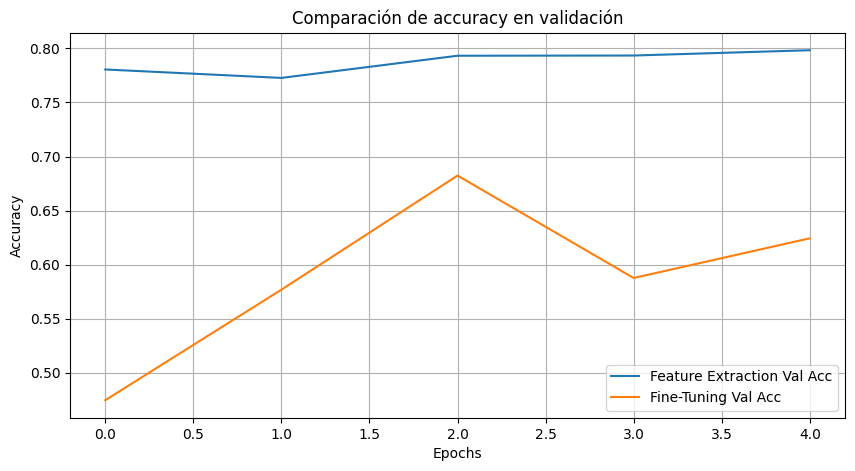

In [7]:
plot_accuracy([history_fe, history_ft], ['Feature Extraction', 'Fine-Tuning'])

Instrucción:

Entrenar ambas versiones por 5 épocas y comparar el accuracy final.

Solución esperada:

Feature extraction: más rápido entrenamiento, menor riesgo de overfitting.

Fine-tuning: mejor precisión si se tienen suficientes datos y regularización adecuada.

